Este cuaderno valida la vista minable y analiza qué grupos presentan más ausencias. Compara tasas por recordatorio SMS, antelación, primera visita y seguro; los gráficos muestran también el tamaño de cada grupo. Las conclusiones son descriptivas, no predicciones individuales.


## Cargar la vista y definir el objetivo

Se lee el CSV final y se indica la variable que se quiere explicar. `columnas_fuga` permite anotar campos que no deben aparecer en la vista.

In [5]:
import pandas as pd
import numpy as np

df_vista = pd.read_csv("../../data/processed/sonrievalencia_citas_final.csv", sep=";")

col_objetivo = "no_acude"
columnas_fuga = []
import matplotlib.pyplot as plt
import seaborn as sns


## Comprobar estructura y datos ausentes

Estas comprobaciones verifican que haya registros, columnas útiles y ningún valor ausente.

In [6]:
assert not df_vista.empty, "ERROR: El DataFrame está vacío."
assert (
    df_vista.shape[0] > 0 and df_vista.shape[1] > 1
), f"ERROR: Dimensiones inválidas {df_vista.shape}."

nulos_totales = df_vista.isna().sum().sum()
assert nulos_totales == 0, (
    f"ERROR: Se han encontrado {nulos_totales} valores nulos."
)

cols_no_numericas = df_vista.select_dtypes(
    exclude=[np.number, "bool"]
).columns.tolist()
identificadores = ["id_cita"]
df_vista = df_vista.drop(columns=identificadores)

cols_no_numericas = df_vista.select_dtypes(
    exclude=[np.number, "bool"]
).columns.tolist()
assert len(cols_no_numericas) == 0, (
    f"ERROR: Existen columnas no numéricas: {cols_no_numericas}"
)

valores_inf = np.isinf(
    df_vista.select_dtypes(include=[np.number])
).values.any()
assert not valores_inf, (
    "ERROR: Existen valores infinitos (inf / -inf) en el DataFrame."
)

## Comprobar variables y objetivo

Se descartan columnas sin variación y duplicados, y se valida que `no_acude` sea binaria y que no queden las columnas de fuga indicadas.

In [7]:
cols_constantes = [
    col for col in df_vista.columns
    if df_vista[col].nunique() <= 1
]
assert len(cols_constantes) == 0, (
    f"ERROR: Existen columnas constantes sin varianza: {cols_constantes}"
)

duplicados = df_vista.duplicated().sum()
assert duplicados == 0, f"ERROR: Hay {duplicados} filas duplicadas."

assert col_objetivo in df_vista.columns, (
    f"ERROR: No se encuentra la variable objetivo '{col_objetivo}'."
)
valores_target = set(df_vista[col_objetivo].unique())
assert valores_target.issubset({0, 1}), (
    "ERROR: La variable objetivo debe ser binaria (0/1), "
    f"encontrado: {valores_target}"
)

fugas_encontradas = [
    col for col in columnas_fuga
    if col in df_vista.columns
]
assert len(fugas_encontradas) == 0, (
    f"ERROR: Se detectan columnas con fuga de datos: {fugas_encontradas}"
)

## Resumen de la validación

Si se llega a esta celda, las comprobaciones anteriores se han superado.

In [8]:
print("TODOS LOS ASSERTS SUPERADOS CORRECTAMENTE")
print(
    f"Resumen de la vista minable: "
    f"{df_vista.shape[0]} filas x {df_vista.shape[1]} columnas."
)
print(
    f"Distribución de '{col_objetivo}':\n"
    f"{df_vista[col_objetivo].value_counts(normalize=True).round(4) * 100}"
)

TODOS LOS ASSERTS SUPERADOS CORRECTAMENTE
Resumen de la vista minable: 2400 filas x 37 columnas.
Distribución de 'no_acude':
no_acude
0    78.46
1    21.54
Name: proportion, dtype: float64


## Primera lectura de las asociaciones

La correlación ayuda a ordenar las variables para explorarlas, pero no equivale a una probabilidad de ausencia. A continuación se comparan tasas observadas por grupo y se muestran sus tamaños; las diferencias no demuestran causalidad.


In [9]:

tasa_absentismo = df_vista[col_objetivo].mean() * 100
print(f"📌 Tasa media de citas perdidas en la clínica: {tasa_absentismo:.2f}%\n")

correlaciones = (
    df_vista.corr(numeric_only=True)[col_objetivo]
    .drop(col_objetivo)
    .sort_values(key=abs, ascending=False)
)

print("🔎 Top variables más asociadas a NO acudir a la cita:")
for var, corr in correlaciones.head(10).items():
    direccion = "⬆️ Aumenta riesgo" if corr > 0 else "⬇️ Reduce riesgo"
    print(f"  - {var:<30} | corr: {corr:+.3f} ({direccion})")

top_vars = correlaciones.head(6).index.tolist()
print("\n📊 Perfil medio comparado (0 = Acude | 1 = No acude):")
print(df_vista.groupby(col_objetivo)[top_vars].mean().T.round(2))

📌 Tasa media de citas perdidas en la clínica: 21.54%

🔎 Top variables más asociadas a NO acudir a la cita:
  - recordatorio_sms               | corr: -0.132 (⬇️ Reduce riesgo)
  - dias_antelacion                | corr: +0.126 (⬆️ Aumenta riesgo)
  - seguro_Sin seguro              | corr: +0.085 (⬆️ Aumenta riesgo)
  - seguro_Mutua                   | corr: -0.070 (⬇️ Reduce riesgo)
  - urgencia                       | corr: -0.070 (⬇️ Reduce riesgo)
  - primera_visita                 | corr: +0.066 (⬆️ Aumenta riesgo)
  - visitas_previas                | corr: -0.047 (⬇️ Reduce riesgo)
  - rango_edad_Joven               | corr: -0.042 (⬇️ Reduce riesgo)
  - rango_edad_Senior              | corr: +0.040 (⬆️ Aumenta riesgo)
  - tratamiento_Endodoncia         | corr: +0.032 (⬆️ Aumenta riesgo)

📊 Perfil medio comparado (0 = Acude | 1 = No acude):
no_acude               0      1
recordatorio_sms    0.67   0.51
dias_antelacion    27.83  33.23
seguro_Sin seguro   0.28   0.37
seguro_Mutua    

### 7.2. ¿Qué pacientes no acudirán a su cita?

En los **2.400 registros**, hubo **517 ausencias (21,5 %)**. No se puede saber con certeza qué persona faltará a partir de estas comparaciones, pero sí describir qué grupos tuvieron más ausencias:

- **`recordatorio_sms = No`:** faltó el **28,7 %** (252 de 878), frente al **17,4 %** con `Sí` (265 de 1.522). La categoría `No` también incluye los valores ausentes que se rellenaron como `No` durante la limpieza.
- **Primera visita:** faltó el **27,1 %** (127 de 469), frente al **20,2 %** en visitas posteriores (390 de 1.931).
- **Cita reservada con 31–60 días de antelación:** faltó el **27,1 %** (318 de 1.173). Para reservas con hasta 30 días de antelación, la tasa fue del **16,2 %** (199 de 1.227).
- **Sin seguro registrado:** la tasa fue del **26,9 %**; en pacientes con Mutua fue del **16,5 %** y con seguro privado, del **20,8 %**.

La combinación de **primera visita y `recordatorio_sms = No`** registró un **34,2 %** de ausencias (55 de 161), el grupo más alto entre las combinaciones mostradas. Es una señal útil para priorizar confirmaciones, no una regla para clasificar a cada paciente: incluso en ese grupo la mayoría acudió.

Las cifras describen este conjunto de datos y pueden reflejar otros factores. No prueban que enviar un SMS evite por sí solo la ausencia; para estimar el riesgo individual haría falta entrenar y validar un modelo con datos disponibles antes de la cita.


#### Tasa de ausencia por características registradas

Se comparan el recordatorio, si es la primera visita y el tipo de seguro. La línea discontinua marca la tasa global; las etiquetas muestran el número de citas de cada grupo.


,Grupo,Citas,Tasa de ausencia
6,Mutua,589,16.5%
1,Recordatorio: Sí,1522,17.4%
3,Visita posterior,1931,20.2%
5,Seguro privado,1097,20.8%
4,Sin seguro,714,26.9%
2,Primera visita,469,27.1%
0,Recordatorio: No,878,28.7%


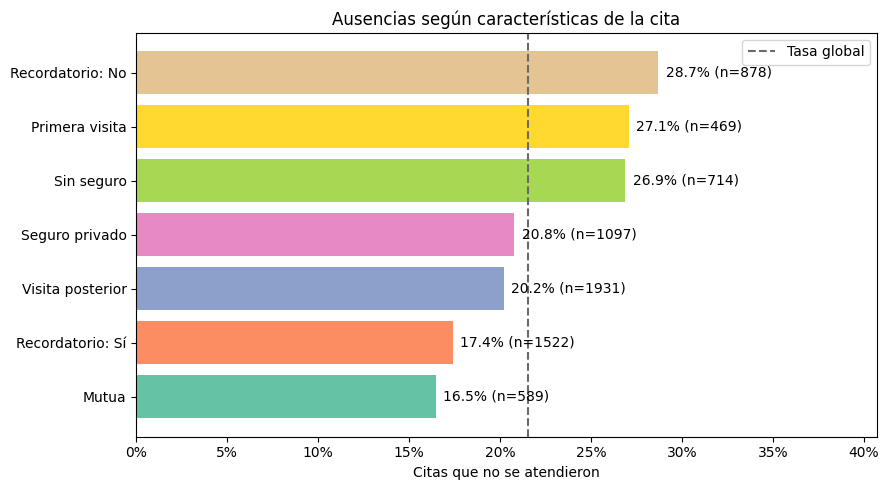

In [10]:
grupos = [
    ("Recordatorio: No", "recordatorio_sms", 0),
    ("Recordatorio: Sí", "recordatorio_sms", 1),
    ("Primera visita", "primera_visita", 1),
    ("Visita posterior", "primera_visita", 0),
    ("Sin seguro", "seguro_Sin seguro", 1),
    ("Seguro privado", "seguro_Privado", 1),
    ("Mutua", "seguro_Mutua", 1),
]

filas = []
for etiqueta, columna, valor in grupos:
    citas = df_vista.loc[df_vista[columna] == valor, col_objetivo]
    filas.append({
        "Grupo": etiqueta,
        "Citas": len(citas),
        "Tasa de ausencia": citas.mean(),
    })

resumen_grupos = pd.DataFrame(filas).sort_values("Tasa de ausencia")
tabla_grupos = resumen_grupos.assign(
    **{
        "Tasa de ausencia": resumen_grupos["Tasa de ausencia"].map(
            lambda tasa: f"{tasa:.1%}"
        )
    }
)
display(tabla_grupos)

fig, ax = plt.subplots(figsize=(9, 5))
colores = sns.color_palette("Set2", n_colors=len(resumen_grupos))
barras = ax.barh(
    resumen_grupos["Grupo"],
    resumen_grupos["Tasa de ausencia"],
    color=colores,
)
ax.axvline(
    df_vista[col_objetivo].mean(),
    color="dimgray",
    linestyle="--",
    label="Tasa global",
)

for barra, (_, fila) in zip(barras, resumen_grupos.iterrows()):
    ax.text(
        barra.get_width() + 0.004,
        barra.get_y() + barra.get_height() / 2,
        f"{fila['Tasa de ausencia']:.1%} (n={int(fila['Citas'])})",
        va="center",
    )

ax.set(
    title="Ausencias según características de la cita",
    xlabel="Citas que no se atendieron",
    ylabel="",
    xlim=(0, resumen_grupos["Tasa de ausencia"].max() + 0.12),
)
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda valor, _: f"{valor:.0%}"))
ax.legend()
plt.tight_layout()
plt.show()

#### Antelación de la reserva

Los intervalos permiten comprobar si las citas reservadas con más tiempo presentan una tasa de ausencia distinta.


,Citas,Tasa
tramo_antelacion,,
0–7,354,14.7%
8–14,295,17.6%
15–30,578,16.4%
31–60,1173,27.1%


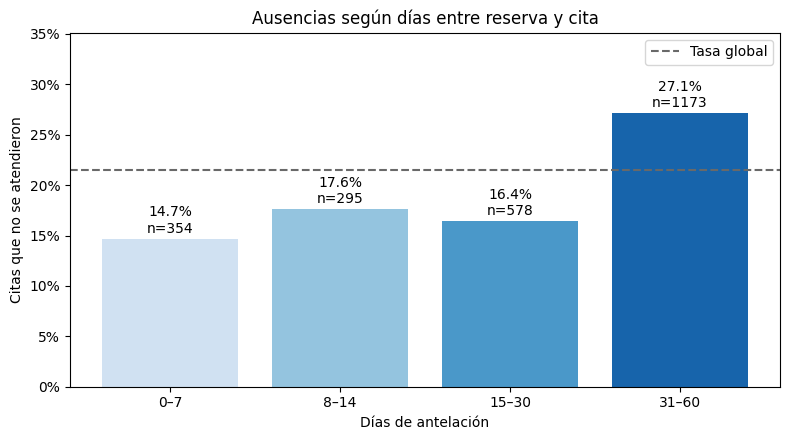

In [11]:
tramos_antelacion = ["0–7", "8–14", "15–30", "31–60"]
df_vista["tramo_antelacion"] = pd.cut(
    df_vista["dias_antelacion"],
    bins=[-1, 7, 14, 30, 60],
    labels=tramos_antelacion,
    include_lowest=True,
)

resumen_antelacion = (
    df_vista.groupby("tramo_antelacion", observed=False)[col_objetivo]
    .agg(Citas="size", Tasa="mean")
    .dropna()
    .reindex(tramos_antelacion)
)
display(resumen_antelacion.assign(
    Tasa=resumen_antelacion["Tasa"].map(lambda tasa: f"{tasa:.1%}")
))

fig, ax = plt.subplots(figsize=(8, 4.5))
barras = ax.bar(
    resumen_antelacion.index.astype(str),
    resumen_antelacion["Tasa"],
    color=sns.color_palette("Blues", n_colors=len(resumen_antelacion)),
)
ax.axhline(
    df_vista[col_objetivo].mean(),
    color="dimgray",
    linestyle="--",
    label="Tasa global",
)

for barra, (_, fila) in zip(barras, resumen_antelacion.iterrows()):
    ax.text(
        barra.get_x() + barra.get_width() / 2,
        barra.get_height() + 0.006,
        f"{fila['Tasa']:.1%}\nn={int(fila['Citas'])}",
        ha="center",
    )

ax.set(
    title="Ausencias según días entre reserva y cita",
    xlabel="Días de antelación",
    ylabel="Citas que no se atendieron",
    ylim=(0, resumen_antelacion["Tasa"].max() + 0.08),
)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda valor, _: f"{valor:.0%}"))
ax.legend()
plt.tight_layout()
plt.show()

#### Recordatorio y primera visita en conjunto

Este último gráfico combina los dos factores con diferencias más claras y ayuda a ver el tamaño de cada grupo junto a su tasa.


,Perfil,Citas,Tasa
2,SMS = Sí · Visita posterior,1214,15.9%
3,SMS = Sí · Primera visita,308,23.4%
0,SMS = No · Visita posterior,717,27.5%
1,SMS = No · Primera visita,161,34.2%


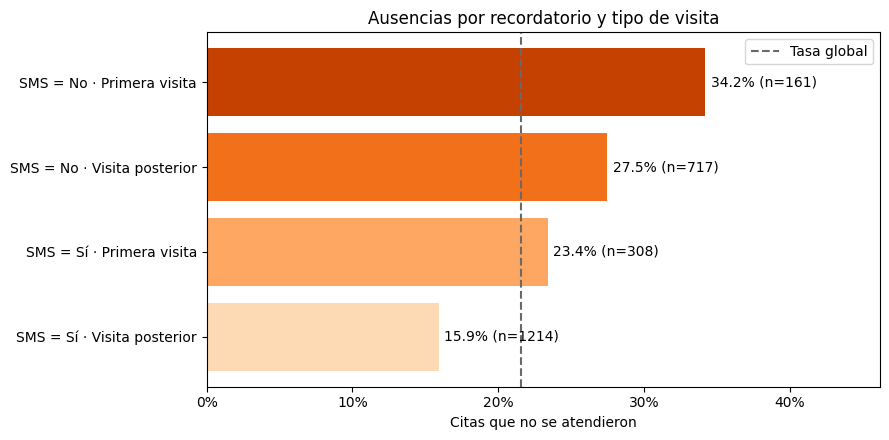

In [12]:
combinaciones = (
    df_vista.groupby(["recordatorio_sms", "primera_visita"])[col_objetivo]
    .agg(Citas="size", Tasa="mean")
    .reset_index()
)

combinaciones["Perfil"] = combinaciones.apply(
    lambda fila: (
        ("SMS = Sí" if fila["recordatorio_sms"] == 1 else "SMS = No")
        + " · "
        + ("Primera visita" if fila["primera_visita"] == 1 else "Visita posterior")
    ),
    axis=1,
)
combinaciones = combinaciones.sort_values("Tasa")
tabla_combinaciones = combinaciones[["Perfil", "Citas", "Tasa"]].copy()
tabla_combinaciones["Tasa"] = tabla_combinaciones["Tasa"].map(
    lambda tasa: f"{tasa:.1%}"
)
display(tabla_combinaciones)

fig, ax = plt.subplots(figsize=(9, 4.5))
barras = ax.barh(
    combinaciones["Perfil"],
    combinaciones["Tasa"],
    color=sns.color_palette("Oranges", n_colors=len(combinaciones)),
)
ax.axvline(
    df_vista[col_objetivo].mean(),
    color="dimgray",
    linestyle="--",
    label="Tasa global",
)

for barra, (_, fila) in zip(barras, combinaciones.iterrows()):
    ax.text(
        barra.get_width() + 0.004,
        barra.get_y() + barra.get_height() / 2,
        f"{fila['Tasa']:.1%} (n={int(fila['Citas'])})",
        va="center",
    )

ax.set(
    title="Ausencias por recordatorio y tipo de visita",
    xlabel="Citas que no se atendieron",
    ylabel="",
    xlim=(0, combinaciones["Tasa"].max() + 0.12),
)
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda valor, _: f"{valor:.0%}"))
ax.legend()
plt.tight_layout()
plt.show()